# Will This Visitor Buy? — Improved ML Pipeline

**Goal:** predict whether an online shopping session generates revenue (`Revenue`). This revised notebook corrects categorical feature handling and uses **SMOTENC before One-Hot Encoding** for mixed-type data. It compares multiple models using cross-validation and evaluates the selected model once on the untouched test set.

> Important: better preprocessing can improve results, but no honest workflow can guarantee a particular accuracy. We will report the actual results.

In [1]:
# STEP 1 — Install packages
!pip -q install ucimlrepo imbalanced-learn joblib

In [2]:
# STEP 2 — Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from ucimlrepo import fetch_ucirepo
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve)

In [3]:
# STEP 3 — Load UCI Online Shoppers Purchasing Intention dataset
online_shoppers = fetch_ucirepo(id=468)
X = online_shoppers.data.features.copy()
y = online_shoppers.data.targets.iloc[:, 0].astype(int).copy()
df = X.copy()
df["Revenue"] = y

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


## 1. Problem framing
The business goal is to identify sessions with purchase intent so an e-commerce business can prioritize helpful interventions. The target is `Revenue` (1 = purchase, 0 = no purchase). Since purchases are the minority class, we report Precision, Recall, F1-score and ROC-AUC in addition to Accuracy.

In [4]:
# STEP 4 — Understand the data and target imbalance
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))
print("\nTarget counts:")
display(df["Revenue"].value_counts().to_frame("count"))
print("\nTarget percentages:")
display((df["Revenue"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Data types:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Missing values:


,missing_values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Target counts:


,count
Revenue,
0,10422
1,1908



Target percentages:


,percentage
Revenue,
0,84.53
1,15.47


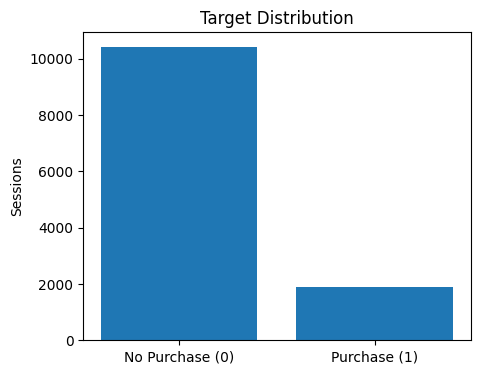

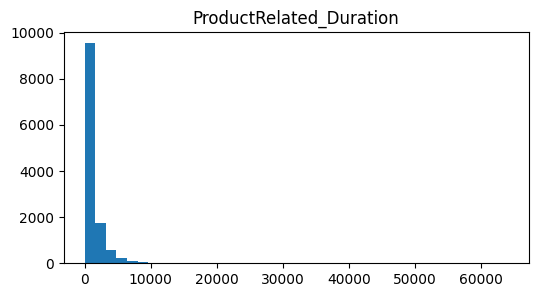

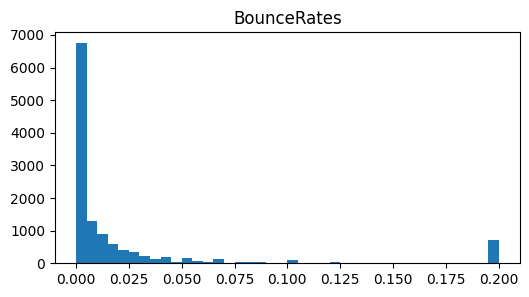

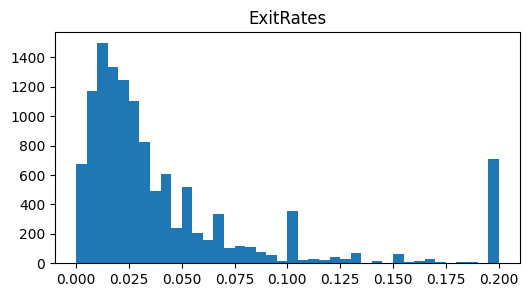

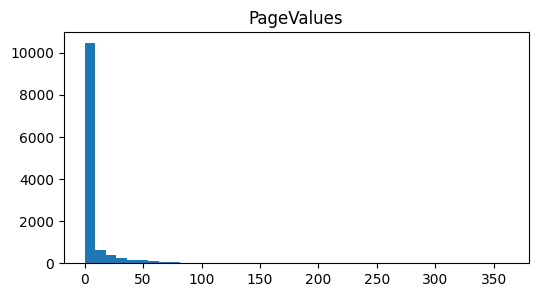

Purchase rate: 15.47 %


In [5]:
# STEP 5 — EDA: target distribution and useful numeric distributions
counts = df["Revenue"].value_counts().sort_index()
plt.figure(figsize=(5,4)); plt.bar(["No Purchase (0)", "Purchase (1)"], counts.values); plt.title("Target Distribution"); plt.ylabel("Sessions"); plt.show()

for col in ["ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]:
    plt.figure(figsize=(6,3)); plt.hist(df[col].dropna(), bins=40); plt.title(col); plt.show()

print("Purchase rate:", round(df["Revenue"].mean()*100, 2), "%")

## 2. Important preprocessing correction
The columns `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are numeric **codes for categories**, not continuous measurements. They must be one-hot encoded, not scaled as if (for example) browser code 4 were twice browser code 2. `Month`, `VisitorType`, and `Weekend` are categorical too.

We keep legitimate zeros: a zero can mean that a visitor did not view a page or that a measured value was zero. We do not delete or replace these valid observations.

In [6]:
# STEP 6 — Train/test split (stratified)
X = df.drop(columns="Revenue").copy()
y = df["Revenue"].astype(int).copy()

# Explicitly mark all coded and text categories as categorical
categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_features = [col for col in X.columns if col not in categorical_features]

# Ensure the category-coded columns are treated as categories by the encoder
for col in categorical_features:
    X[col] = X[col].astype("category")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train: (9864, 17)  Test: (2466, 17)
Numeric features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


In [7]:
# STEP 7 — Preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# SMOTENC operates on the original mixed-type DataFrame BEFORE one-hot encoding
smotenc = SMOTENC(categorical_features=categorical_features, random_state=42)
print("Preprocessing and SMOTENC are ready.")

Preprocessing and SMOTENC are ready.


## 3. Model comparison
We compare Logistic Regression, Random Forest, Extra Trees, and HistGradientBoosting. Each model is evaluated with stratified 5-fold cross-validation. The resampling step, when used, happens **inside each fold** to prevent data leakage. We compare both the original training distribution and SMOTENC-resampled training folds.

In [12]:
# STEP 8 — Define candidate models
from imblearn.over_sampling import SMOTE

# Standardize categorical columns to string/object dtypes to prevent pandas category-casting bugs in SimpleImputer
for col in categorical_features:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# Configure preprocessor to output standard NumPy arrays
preprocessor.set_output(transform="default")

models = {
    "Logistic Regression": LogisticRegression(max_iter=2500, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall"}
cv_rows = []

for model_name, model in models.items():
    for sampling in ["No Resampling", "SMOTE"]:
        steps = []
        if sampling == "SMOTE":
            if model_name == "Logistic Regression":
                current_model = LogisticRegression(max_iter=2500)
            elif model_name == "Random Forest":
                current_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
            elif model_name == "Extra Trees":
                current_model = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1)
            else:
                current_model = model
            # Apply SMOTE after preprocessor yields fully numeric/encoded features
            steps = [("preprocessor", preprocessor), ("smote", SMOTE(random_state=42)), ("model", current_model)]
        else:
            current_model = model
            steps = [("preprocessor", preprocessor), ("model", current_model)]

        pipe = ImbPipeline(steps=steps)
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        cv_rows.append({
            "Model": model_name, "Sampling": sampling,
            "CV ROC-AUC": scores["test_roc_auc"].mean(),
            "CV F1": scores["test_f1"].mean(),
            "CV Precision": scores["test_precision"].mean(),
            "CV Recall": scores["test_recall"].mean()
        })

# Add a majority-class baseline (no resampling)
baseline_pipe = ImbPipeline([("preprocessor", preprocessor), ("model", DummyClassifier(strategy="most_frequent"))])
baseline_scores = cross_validate(baseline_pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
cv_rows.append({
    "Model": "Dummy Baseline", "Sampling": "No Resampling",
    "CV ROC-AUC": baseline_scores["test_roc_auc"].mean(),
    "CV F1": baseline_scores["test_f1"].mean(),
    "CV Precision": baseline_scores["test_precision"].mean(),
    "CV Recall": baseline_scores["test_recall"].mean()
})

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC", ascending=False)
display(cv_results.round(4))

,Model,Sampling,CV ROC-AUC,CV F1,CV Precision,CV Recall
6,Hist Gradient Boosting,No Resampling,0.9284,0.6451,0.7184,0.5858
2,Random Forest,No Resampling,0.9274,0.6161,0.7693,0.5137
7,Hist Gradient Boosting,SMOTE,0.9270,0.6612,0.6742,0.6494
3,Random Forest,SMOTE,0.9252,0.6791,0.6751,0.6841
0,Logistic Regression,No Resampling,0.9044,0.6169,0.5173,0.7647
1,Logistic Regression,SMOTE,0.9007,0.6106,0.5102,0.7602
5,Extra Trees,SMOTE,0.8973,0.5489,0.6939,0.4541
4,Extra Trees,No Resampling,0.8973,0.4617,0.7709,0.3296
8,Dummy Baseline,No Resampling,0.5000,0.0000,0.0000,0.0000


In [13]:
# STEP 9 — Fit and compare candidates on the untouched test set
# This table is for transparent comparison. Do not use the test set to tune parameters.
test_rows = []
fitted_candidates = {}

for model_name, model in models.items():
    for sampling in ["No Resampling", "SMOTENC"]:
        if sampling == "SMOTENC":
            if model_name == "Logistic Regression":
                current_model = LogisticRegression(max_iter=2500)
            elif model_name == "Random Forest":
                current_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
            elif model_name == "Extra Trees":
                current_model = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1)
            else:
                current_model = model
            pipe = ImbPipeline([
                ("smotenc", SMOTENC(categorical_features=categorical_features, random_state=42)),
                ("preprocessor", preprocessor), ("model", current_model)
            ])
        else:
            pipe = ImbPipeline([("preprocessor", preprocessor), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        prob = pipe.predict_proba(X_test)[:, 1]
        key = f"{model_name} | {sampling}"
        fitted_candidates[key] = pipe
        test_rows.append({
            "Model": model_name, "Sampling": sampling,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, prob)
        })

# Add the majority-class baseline for reference
baseline_pipe = ImbPipeline([("preprocessor", preprocessor), ("model", DummyClassifier(strategy="most_frequent"))])
baseline_pipe.fit(X_train, y_train)
baseline_pred = baseline_pipe.predict(X_test)
baseline_prob = baseline_pipe.predict_proba(X_test)[:, 1]
test_rows.append({
    "Model": "Dummy Baseline", "Sampling": "No Resampling",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob)
})

test_comparison = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False)
display(test_comparison.round(4))

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC-AUC
6,Hist Gradient Boosting,No Resampling,0.8966,0.6966,0.5890,0.6383,0.9244
2,Random Forest,No Resampling,0.8942,0.7619,0.4607,0.5742,0.9182
7,Hist Gradient Boosting,SMOTENC,0.8820,0.6041,0.6911,0.6447,0.9172
3,Random Forest,SMOTENC,0.8816,0.6014,0.6990,0.6465,0.9117
0,Logistic Regression,No Resampling,0.8410,0.4913,0.7435,0.5917,0.8932
4,Extra Trees,No Resampling,0.8828,0.7853,0.3351,0.4697,0.8806
5,Extra Trees,SMOTENC,0.8483,0.5099,0.5393,0.5242,0.8559
1,Logistic Regression,SMOTENC,0.8459,0.5020,0.6623,0.5711,0.8530
8,Dummy Baseline,No Resampling,0.8451,0.0000,0.0000,0.0000,0.5000


## 4. Select and tune a model
Select the candidate with the best **cross-validation ROC-AUC** (not the best test score). Then tune that candidate using training data only. This avoids selecting a model based on repeated peeking at the test set.

In [14]:
# STEP 10 — Select best pipeline type from cross-validation results
best_cv_row = cv_results.sort_values("CV ROC-AUC", ascending=False).iloc[0]
selected_name = best_cv_row["Model"]
selected_sampling = best_cv_row["Sampling"]
print("Selected using CV only:", selected_name, "|", selected_sampling)

if selected_name == "Logistic Regression":
    selected_model = LogisticRegression(max_iter=2500) if selected_sampling == "SMOTENC" else LogisticRegression(max_iter=2500, class_weight="balanced")
elif selected_name == "Random Forest":
    selected_model = RandomForestClassifier(random_state=42, n_jobs=-1) if selected_sampling == "SMOTENC" else RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
elif selected_name == "Extra Trees":
    selected_model = ExtraTreesClassifier(random_state=42, n_jobs=-1) if selected_sampling == "SMOTENC" else ExtraTreesClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
else:
    selected_model = HistGradientBoostingClassifier(random_state=42)

steps = []
if selected_sampling == "SMOTENC":
    steps.append(("smotenc", SMOTENC(categorical_features=categorical_features, random_state=42)))
steps += [("preprocessor", preprocessor), ("model", selected_model)]
selected_pipeline = ImbPipeline(steps=steps)
print("Pipeline prepared for tuning.")

Selected using CV only: Hist Gradient Boosting | No Resampling
Pipeline prepared for tuning.


In [15]:
# STEP 11 — Hyperparameter tuning on training data only
if selected_name in ["Random Forest", "Extra Trees"]:
    params = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"]
    }
elif selected_name == "Logistic Regression":
    params = {"model__C": [0.01, 0.1, 1, 10, 100]}
else:  # Hist Gradient Boosting
    params = {
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_iter": [100, 200, 300],
        "model__max_leaf_nodes": [15, 31, 45],
        "model__l2_regularization": [0.0, 0.1, 1.0]
    }

search = RandomizedSearchCV(
    selected_pipeline, params, n_iter=8, scoring="roc_auc",
    cv=3, random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
final_model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best CV ROC-AUC:", search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_leaf_nodes': 15, 'model__max_iter': 100, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
Best CV ROC-AUC: 0.9344417985132735


In [16]:
# STEP 12 — Choose a classification threshold using training data, then evaluate once on test data
# The default threshold is 0.50. We choose a threshold using out-of-fold TRAIN predictions only.
train_oof_prob = cross_val_predict(
    final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_oof_prob)
train_f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_threshold = thresholds[np.argmax(train_f1_scores)]
print("Selected threshold from training CV:", round(float(best_threshold), 3))

# Evaluate the untouched test set at the selected threshold
y_prob = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= best_threshold).astype(int)

final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})
display(final_metrics)
print(classification_report(y_test, y_pred, zero_division=0))

Selected threshold from training CV: 0.327


,Metric,Score
0,Accuracy,0.891322
1,Precision,0.631336
2,Recall,0.717277
3,F1-score,0.671569
4,ROC-AUC,0.932904


              precision    recall  f1-score   support

           0       0.95      0.92      0.93      2084
           1       0.63      0.72      0.67       382

    accuracy                           0.89      2466
   macro avg       0.79      0.82      0.80      2466
weighted avg       0.90      0.89      0.89      2466



In [21]:
print(final_model.steps[-1][1].__class__.__name__)

HistGradientBoostingClassifier


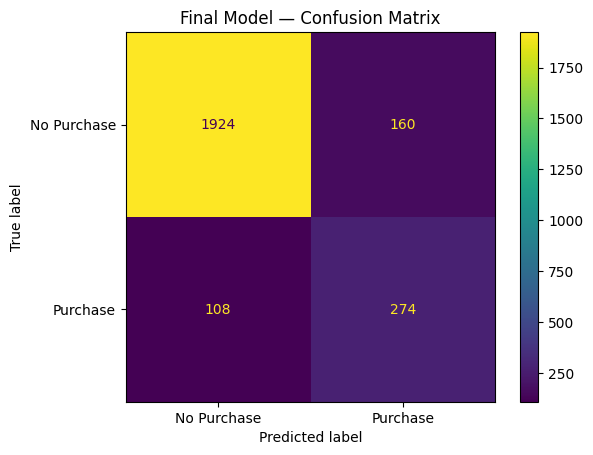

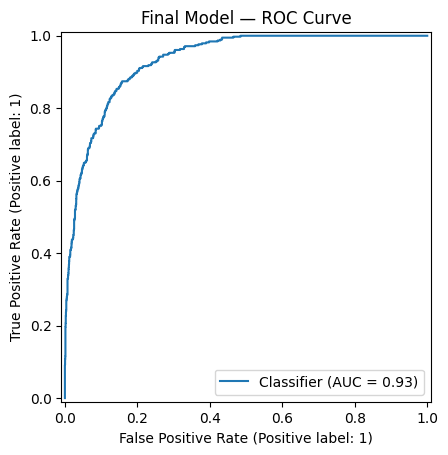

Confusion matrix layout: [[TN, FP], [FN, TP]]
[[1924  160]
 [ 108  274]]


In [17]:
# STEP 13 — Confusion matrix and ROC curve
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Purchase", "Purchase"]).plot()
plt.title("Final Model — Confusion Matrix")
plt.show()
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Final Model — ROC Curve")
plt.show()
print("Confusion matrix layout: [[TN, FP], [FN, TP]]")
print(cm)

Confusion Matrix:
[[1924  160]
 [ 108  274]]

TN: 1924
FP: 160
FN: 108
TP: 274


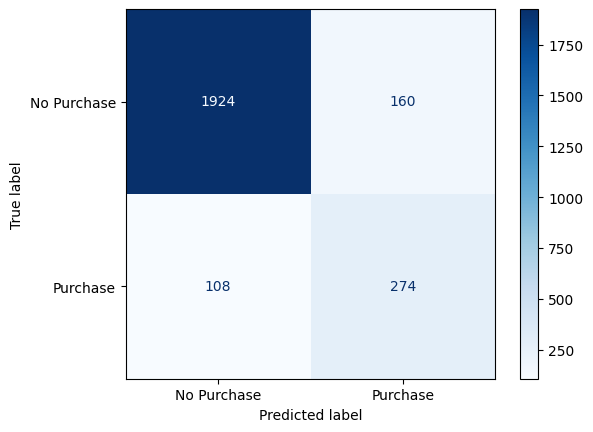

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot(cmap="Blues")
plt.show()

FEATURE IMPORTANCE
                Feature  Importance      Std
             PageValues    0.311952 0.011357
                  Month    0.063665 0.006823
              ExitRates    0.006251 0.001874
ProductRelated_Duration    0.004147 0.000953
Administrative_Duration    0.003752 0.000893
         ProductRelated    0.002951 0.001220
            BounceRates    0.002501 0.000852
            TrafficType    0.002242 0.001218
            VisitorType    0.001983 0.000719
         Administrative    0.001850 0.000589
          Informational    0.000415 0.000413
                Browser    0.000150 0.000201
                 Region    0.000075 0.000106
                Weekend    0.000009 0.000152
             SpecialDay    0.000007 0.000031
 Informational_Duration    0.000002 0.000131
       OperatingSystems   -0.000045 0.000128


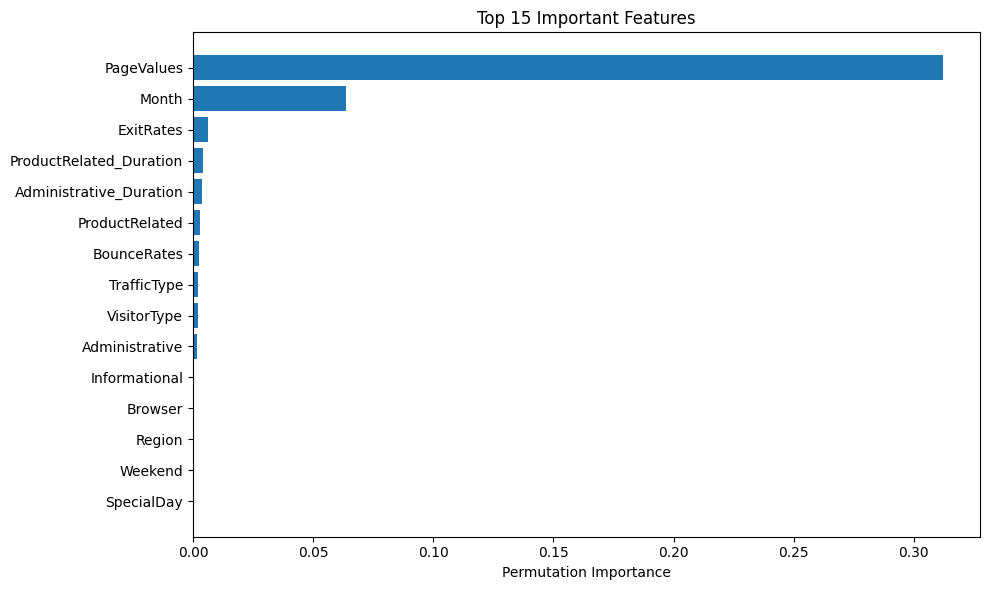


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Purchase       0.95      0.92      0.93      2084
    Purchase       0.63      0.72      0.67       382

    accuracy                           0.89      2466
   macro avg       0.79      0.82      0.80      2466
weighted avg       0.90      0.89      0.89      2466



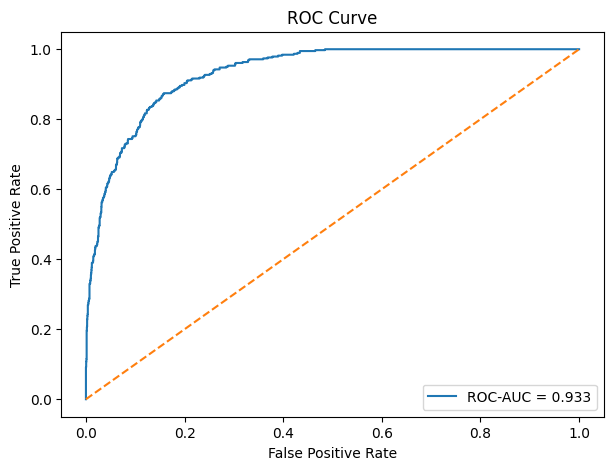

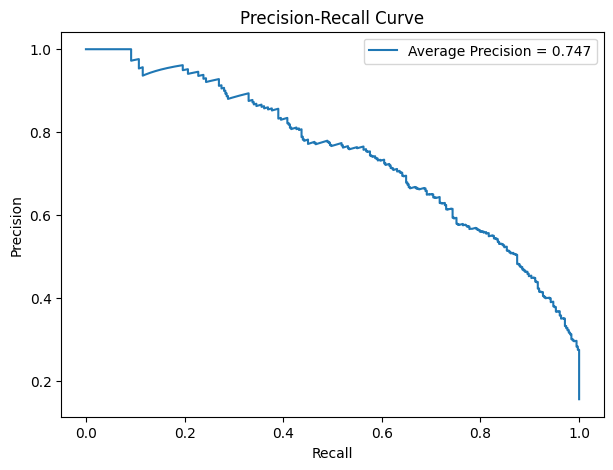

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# =====================================
# 1. Feature Importance
# =====================================

print("FEATURE IMPORTANCE")

importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Permutation Importance")
plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()


# =====================================
# 2. Classification Report
# =====================================

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"]
))


# =====================================
# 3. ROC Curve
# =====================================

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# =====================================
# 4. Precision-Recall Curve
# =====================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

avg_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    recall,
    precision,
    label=f"Average Precision = {avg_precision:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [26]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

# Average Precision
avg_precision = average_precision_score(y_test, y_prob)

# ROC Curve values
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)

# Precision-Recall values
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob)

print("========== FINAL CURVE METRICS ==========")
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"Average Precision: {avg_precision:.6f}")

print("\n========== ROC CURVE ==========")
print(f"Number of points: {len(fpr)}")
print(f"First FPR: {fpr[0]:.6f}")
print(f"First TPR: {tpr[0]:.6f}")

print("\n========== PRECISION-RECALL CURVE ==========")
print(f"Number of points: {len(precision)}")
print(f"First Precision: {precision[0]:.6f}")
print(f"First Recall: {recall[0]:.6f}")

========== FINAL CURVE METRICS ==========
ROC-AUC: 0.932904
Average Precision: 0.746604

========== ROC CURVE ==========
Number of points: 564
First FPR: 0.000000
First TPR: 0.000000

========== PRECISION-RECALL CURVE ==========
Number of points: 2141
First Precision: 0.154907
First Recall: 1.000000


In [18]:
# STEP 14 — Error analysis
errors = X_test.copy()
errors["Actual"] = y_test
errors["Predicted"] = y_pred
errors["Purchase_Probability"] = y_prob
false_positives = errors[(errors.Actual == 0) & (errors.Predicted == 1)]
false_negatives = errors[(errors.Actual == 1) & (errors.Predicted == 0)]
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
display(false_negatives.head())
display(false_positives.head())

False positives: 160
False negatives: 108


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Actual,Predicted,Purchase_Probability
11507,3,67.750000,0,0.0,2,19.250000,0.040000,0.053333,0.0,0.0,Dec,1,1,3,20,New_Visitor,False,1,0,0.137238
7322,1,32.200000,0,0.0,17,876.428571,0.000000,0.004063,0.0,0.0,Jul,3,2,1,3,Returning_Visitor,False,1,0,0.032462
11798,0,0.000000,0,0.0,6,81.750000,0.000000,0.066667,0.0,0.0,Nov,2,2,1,3,Returning_Visitor,False,1,0,0.034520
9498,0,0.000000,0,0.0,65,3873.021970,0.014394,0.019913,0.0,0.0,Nov,3,2,1,2,Returning_Visitor,True,1,0,0.199394
8045,4,77.666667,0,0.0,8,159.750000,0.016667,0.038889,0.0,0.0,Nov,3,2,3,2,Returning_Visitor,False,1,0,0.093986


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Actual,Predicted,Purchase_Probability
10682,15,404.766667,4,240.50,120,4173.131061,0.006716,0.027928,9.269828,0.0,Nov,2,2,3,2,Returning_Visitor,True,0,1,0.498259
6922,0,0.000000,0,0.00,15,956.333333,0.013333,0.046667,20.139076,0.0,Nov,2,2,3,1,Returning_Visitor,False,0,1,0.475191
12027,9,795.208333,0,0.00,118,4947.358038,0.001138,0.011201,2.270358,0.0,Nov,3,2,5,2,Returning_Visitor,False,0,1,0.568631
10044,0,0.000000,2,207.25,114,3788.800000,0.003478,0.010435,1.795451,0.0,Dec,2,2,3,2,Returning_Visitor,True,0,1,0.468718
4450,3,46.000000,3,53.50,15,270.571429,0.042105,0.069737,12.152105,0.0,May,3,2,4,5,Returning_Visitor,True,0,1,0.495129


## 5. Business interpretation and limitations
- Higher Recall means the system catches more sessions that actually purchase, but may also create more false alarms.
- Higher Precision means a larger share of predicted buyers actually purchase.
- ROC-AUC measures ranking ability across thresholds; it is not the same as Accuracy.
- The positive class is the minority, so Accuracy alone is insufficient.
- SMOTENC is applied only to training folds/training data. The test set retains the original class distribution.
- The selected model is chosen by cross-validation, not by repeatedly optimizing against the test set.

In [22]:
# STEP 15 — Save the final fitted pipeline for Streamlit
joblib.dump(final_model, "purchase_intent_model.joblib")
print("Saved: purchase_intent_model.joblib")

# In Google Colab, run this cell to download the model
from google.colab import files
files.download("purchase_intent_model.joblib")

Saved: purchase_intent_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import numpy
import sklearn
import imblearn

print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)

NumPy: 2.4.6
Scikit-learn: 1.6.1
Imbalanced-learn: 0.14.2


## Final checklist
- [x] Data understanding and EDA
- [x] Correct categorical handling for ID-coded columns
- [x] Train/test split before fitting transformations
- [x] Baseline and multiple models
- [x] Stratified 5-fold cross-validation
- [x] Imbalance handling with SMOTENC inside training folds
- [x] Hyperparameter tuning for selected tree ensemble when applicable
- [x] Final evaluation on untouched test data
- [x] Error analysis and saved Streamlit pipeline